# Customer Analytics & Machine Learning
## 01 — Data Exploration & Quality

### Project Objective

The objective of this project is to analyze customer behaviour for Meridian Retail Group and build a data-driven customer analytics framework covering:

1. Customer segmentation
2. Churn prediction
3. Market basket analysis and product recommendations

This notebook focuses on the first stage of the project: understanding the raw datasets, assessing data quality, identifying important patterns, and creating reusable order-level and customer-level datasets for downstream analysis.

### Objectives of this notebook

- Load and understand all available datasets
- Examine dataset structure, data types and distributions
- Identify missing values and duplicate records
- Detect potential outliers
- Understand date coverage and transaction behaviour
- Convert transaction-level data into an order-level dataset
- Build an initial customer-level overview
- Analyze seasonality
- Document data quality decisions
- Save reusable processed datasets

In [1]:
# Core libraries
import os
import warnings
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

warnings.filterwarnings("ignore")

In [4]:
# Project root
PROJECT_ROOT = Path.cwd().parent

# Data directories
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"

# Output directories
FIGURES_PATH = PROJECT_ROOT / "outputs" / "figures" / "exploration"
TABLES_PATH = PROJECT_ROOT / "outputs" / "tables"

# Create directories if they don't exist
PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DATA_PATH)
print("Processed data:", PROCESSED_DATA_PATH)


Project root: C:\Users\Sejal patil\OneDrive\Documents\meridian_customer_analytics
Raw data: C:\Users\Sejal patil\OneDrive\Documents\meridian_customer_analytics\data\raw
Processed data: C:\Users\Sejal patil\OneDrive\Documents\meridian_customer_analytics\data\processed


In [5]:

file_names = [
    "customers.csv",
    "products.csv",
    "stores.csv",
    "transactions.csv",
    "digital_engagement.csv",
    "support_tickets.csv",
    "churn_labels.csv"
]

# Check that all files exist
missing_files = [
    file for file in file_names
    if not (RAW_DATA_PATH / file).exists()
]

if missing_files:
    print("Missing files:")
    for file in missing_files:
        print("-", file)
else:
    print("All expected files are available.")

All expected files are available.


In [9]:
customers = pd.read_csv(
    RAW_DATA_PATH / "customers.csv",
    parse_dates=["signup_date"]
)

products = pd.read_csv(
    RAW_DATA_PATH / "products.csv"
)

stores = pd.read_csv(
    RAW_DATA_PATH / "stores.csv"
)

transactions = pd.read_csv(
    RAW_DATA_PATH / "transactions.csv",
    parse_dates=["order_datetime"]
)

digital_engagement = pd.read_csv(
    RAW_DATA_PATH / "digital_engagement.csv",
    parse_dates=["year_month"]
)

support_tickets = pd.read_csv(
    RAW_DATA_PATH / "support_tickets.csv",
    parse_dates=["created_at"]
)

churn_labels = pd.read_csv(
    RAW_DATA_PATH / "churn_labels.csv",
    parse_dates=["observation_cutoff"]
)

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [10]:
datasets = {
    "customers": customers,
    "products": products,
    "stores": stores,
    "transactions": transactions,
    "digital_engagement": digital_engagement,
    "support_tickets": support_tickets,
    "churn_labels": churn_labels
}

for name, df in datasets.items():
    print(f"{name:25} {df.shape}")

customers                 (12000, 12)
products                  (391, 9)
stores                    (27, 6)
transactions              (575516, 15)
digital_engagement        (160680, 12)
support_tickets           (10411, 10)
churn_labels              (7237, 4)


In [11]:
dataset_overview = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()],
    "Memory_MB": [
        df.memory_usage(deep=True).sum() / (1024 ** 2)
        for df in datasets.values()
    ]
})

dataset_overview = dataset_overview.reset_index(drop=True)

dataset_overview

,Dataset,Rows,Columns,Memory_MB
0,customers,12000,12,4.36
1,products,391,9,0.13
2,stores,27,6,0.01
3,transactions,575516,15,284.46
4,digital_engagement,160680,12,22.53
5,support_tickets,10411,10,3.29
6,churn_labels,7237,4,0.92


In [12]:
# Display the first 5 rows of every dataset

for name, df in datasets.items():
    print("=" * 80)
    print(name.upper())
    print("=" * 80)
    display(df.head())

CUSTOMERS


,customer_id,signup_date,age,gender,city,country,household_size,acquisition_channel,loyalty_tier,email_opt_in,sms_opt_in,app_installed
0,CUST100000,2025-07-17,28,F,Sharjah,UAE,3,In-Store Signup,Silver,1,1,1
1,CUST100001,2024-10-03,35,M,Riyadh,KSA,4,Organic Search,Silver,1,0,1
2,CUST100002,2022-03-07,24,M,Abu Dhabi,UAE,8,Organic Search,Gold,1,1,1
3,CUST100003,2025-09-16,45,M,Dubai,UAE,3,Paid Social,Gold,0,1,0
4,CUST100004,2022-09-04,45,F,Sharjah,UAE,4,In-Store Signup,Gold,1,0,1


PRODUCTS


,product_id,product_name,brand,category,subcategory,unit_price_aed,unit_cost_aed,is_private_label,shelf_life_days
0,SKU100001,Meridian Essentials Penne 500g,Meridian Essentials,Grocery,Pasta & Rice,22.95,14.34,1,365
1,SKU100002,Kaviro Spaghetti 500g,Kaviro,Grocery,Pasta & Rice,15.95,12.45,0,180
2,SKU100003,Meridian Essentials Fusilli 500g,Meridian Essentials,Grocery,Pasta & Rice,22.45,11.77,1,730
3,SKU100004,Aurelia Basmati Rice 5kg,Aurelia,Grocery,Pasta & Rice,9.95,6.19,0,365
4,SKU100005,Vantar Jasmine Rice 2kg,Vantar,Grocery,Pasta & Rice,7.45,4.79,0,30


STORES


...

,customer_id,year_month,web_sessions,app_sessions,avg_session_minutes,emails_received,emails_opened,emails_clicked,cart_abandonments,wishlist_adds,loyalty_points_earned,loyalty_points_redeemed
0,CUST100000,2025-07-01,1,6,10.40,0,0,0,0,1,0,0
1,CUST100000,2025-08-01,5,3,10.60,4,1,0,1,0,21,0
2,CUST100000,2025-09-01,2,8,7.80,4,2,0,0,0,43,17
3,CUST100000,2025-10-01,1,6,5.80,4,2,1,1,0,0,0
4,CUST100000,2025-11-01,7,7,3.40,5,3,1,2,0,44,0


SUPPORT_TICKETS


,ticket_id,customer_id,created_at,contact_channel,issue_type,priority,first_response_hours,resolution_hours,was_reopened,csat_score
0,TCK508694,CUST110039,2024-08-01 19:32:45,Live Chat,Price Dispute,High,0.70,5.90,0,5
1,TCK506191,CUST107254,2024-08-02 15:20:04,Phone,Product Enquiry,Medium,6.50,30.70,0,5
2,TCK500092,CUST100099,2024-08-02 18:12:27,Phone,Refund Request,Low,5.90,18.90,0,4
3,TCK504845,CUST105765,2024-08-02 18:26:10,WhatsApp,Product Enquiry,Low,9.60,40.30,0,3
4,TCK507302,CUST108438,2024-08-02 20:06:57,Phone,Missing Item,Medium,0.20,19.70,0,4


CHURN_LABELS


,customer_id,observation_cutoff,outcome_window_end,churned
0,CUST100000,2026-04-30,2026-07-31,0
1,CUST100001,2026-04-30,2026-07-31,0
2,CUST100003,2026-04-30,2026-07-31,1
3,CUST100004,2026-04-30,2026-07-31,0
4,CUST100005,2026-04-30,2026-07-31,0


In [13]:
# Display column names for every dataset

for name, df in datasets.items():
    print(f"\n{name}:")
    print(list(df.columns))


customers:
['customer_id', 'signup_date', 'age', 'gender', 'city', 'country', 'household_size', 'acquisition_channel', 'loyalty_tier', 'email_opt_in', 'sms_opt_in', 'app_installed']

products:
['product_id', 'product_name', 'brand', 'category', 'subcategory', 'unit_price_aed', 'unit_cost_aed', 'is_private_label', 'shelf_life_days']

stores:
['store_id', 'store_name', 'city', 'store_format', 'floor_area_sqm', 'opened_year']

transactions:
['order_id', 'customer_id', 'order_date', 'order_datetime', 'channel', 'store_id', 'product_id', 'quantity', 'unit_price_aed', 'discount_pct', 'line_revenue_aed', 'payment_method', 'delivery_type', 'delivery_delay_days', 'is_returned']

digital_engagement:
['customer_id', 'year_month', 'web_sessions', 'app_sessions', 'avg_session_minutes', 'emails_received', 'emails_opened', 'emails_clicked', 'cart_abandonments', 'wishlist_adds', 'loyalty_points_earned', 'loyalty_points_redeemed']

support_tickets:
['ticket_id', 'customer_id', 'created_at', 'contact_c

### Dataset Grain

The datasets have different levels of granularity:

- `customers.csv` → one row per customer
- `products.csv` → one row per product/SKU
- `stores.csv` → one row per physical store
- `transactions.csv` → one row per order line
- `digital_engagement.csv` → one row per customer per month
- `support_tickets.csv` → one row per support ticket
- `churn_labels.csv` → one row per eligible customer

The transaction dataset will therefore need to be aggregated to order level before creating many customer-level behavioural features.

In [14]:
for name, df in datasets.items():
    print("=" * 80)
    print(name.upper())
    print("=" * 80)
    display(
        pd.DataFrame({
            "Column": df.columns,
            "Data Type": df.dtypes.astype(str).values,
            "Non-Null": df.notna().sum().values,
            "Unique": df.nunique().values
        })
    )

CUSTOMERS


,Column,Data Type,Non-Null,Unique
0,customer_id,str,12000,12000
1,signup_date,datetime64[us],12000,1554
2,age,int64,12000,61
3,gender,str,12000,3
4,city,str,12000,8
5,country,str,12000,5
6,household_size,int64,12000,9
7,acquisition_channel,str,12000,7
8,loyalty_tier,str,12000,4
9,email_opt_in,int64,12000,2


PRODUCTS


,Column,Data Type,Non-Null,Unique
0,product_id,str,391,391
1,product_name,str,391,391
2,brand,str,391,17
3,category,str,391,10
4,subcategory,str,391,40
5,unit_price_aed,float64,391,169
6,unit_cost_aed,float64,391,373
7,is_private_label,int64,391,2
8,shelf_life_days,int64,391,7


STORES


...

,Column,Data Type,Non-Null,Unique
0,customer_id,str,160680,12000
1,year_month,datetime64[us],160680,24
2,web_sessions,int64,160680,34
3,app_sessions,int64,160680,48
4,avg_session_minutes,float64,160680,167
5,emails_received,int64,160680,16
6,emails_opened,int64,160680,11
7,emails_clicked,int64,160680,7
8,cart_abandonments,int64,160680,12
9,wishlist_adds,int64,160680,8


SUPPORT_TICKETS


,Column,Data Type,Non-Null,Unique
0,ticket_id,str,10411,10411
1,customer_id,str,10411,5640
2,created_at,datetime64[us],10411,10410
3,contact_channel,str,10411,6
4,issue_type,str,10411,10
5,priority,str,10411,4
6,first_response_hours,float64,10411,275
7,resolution_hours,float64,10411,695
8,was_reopened,int64,10411,2
9,csat_score,int64,10411,5


CHURN_LABELS


,Column,Data Type,Non-Null,Unique
0,customer_id,str,7237,7237
1,observation_cutoff,datetime64[us],7237,1
2,outcome_window_end,str,7237,1
3,churned,int64,7237,2


In [15]:
for name, df in datasets.items():
    print(f"\n{'=' * 80}")
    print(name.upper())
    print(f"{'=' * 80}")
    df.info()


CUSTOMERS
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          12000 non-null  str           
 1   signup_date          12000 non-null  datetime64[us]
 2   age                  12000 non-null  int64         
 3   gender               12000 non-null  str           
 4   city                 12000 non-null  str           
 5   country              12000 non-null  str           
 6   household_size       12000 non-null  int64         
 7   acquisition_channel  12000 non-null  str           
 8   loyalty_tier         12000 non-null  str           
 9   email_opt_in         12000 non-null  int64         
 10  sms_opt_in           12000 non-null  int64         
 11  app_installed        12000 non-null  int64         
dtypes: datetime64[us](1), int64(5), str(6)
memory usage: 1.1 MB

PRODUCTS
<class 'pandas.Dat

In [16]:
missing_summary = {}

for name, df in datasets.items():
    missing_count = df.isna().sum()
    missing_pct = (missing_count / len(df)) * 100
    
    summary = pd.DataFrame({
        "Column": df.columns,
        "Missing_Count": missing_count.values,
        "Missing_Percentage": missing_pct.values
    })
    
    summary = summary[summary["Missing_Count"] > 0]
    
    missing_summary[name] = summary
    
    print("=" * 80)
    print(name.upper())
    print("=" * 80)
    
    if summary.empty:
        print("No missing values found.")
    else:
        display(summary.sort_values(
            "Missing_Percentage",
            ascending=False
        ))

CUSTOMERS
No missing values found.
PRODUCTS
No missing values found.
STORES
No missing values found.
TRANSACTIONS
No missing values found.
DIGITAL_ENGAGEMENT
No missing values found.
SUPPORT_TICKETS
No missing values found.
CHURN_LABELS
No missing values found.


In [17]:
# Overall missing-value summary

all_missing = []

for name, df in datasets.items():
    for column in df.columns:
        count = df[column].isna().sum()
        
        if count > 0:
            all_missing.append({
                "Dataset": name,
                "Column": column,
                "Missing_Count": count,
                "Missing_Percentage": count / len(df) * 100
            })

missing_df = pd.DataFrame(all_missing)

if not missing_df.empty:
    missing_df = missing_df.sort_values(
        "Missing_Percentage",
        ascending=False
    )
    
    display(missing_df)
else:
    print("No missing values across the datasets.")

No missing values across the datasets.


In [18]:
duplicate_summary = []

for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()
    
    duplicate_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Duplicate_Rows": duplicate_count,
        "Duplicate_Percentage": duplicate_count / len(df) * 100
    })

duplicate_summary = pd.DataFrame(duplicate_summary)

duplicate_summary

,Dataset,Rows,Duplicate_Rows,Duplicate_Percentage
0,customers,12000,0,0.00
1,products,391,0,0.00
2,stores,27,0,0.00
3,transactions,575516,0,0.00
4,digital_engagement,160680,0,0.00
5,support_tickets,10411,0,0.00
6,churn_labels,7237,0,0.00


In [19]:
transactions.select_dtypes(include=np.number).describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,"575,516.00",1.55,0.80,1.00,1.00,1.00,2.00,10.00
unit_price_aed,"575,516.00",64.91,147.19,2.45,12.95,25.45,66.95,"1,318.00"
discount_pct,"575,516.00",2.96,7.46,0.00,0.00,0.00,0.00,40.00
line_revenue_aed,"575,516.00",86.50,211.57,1.47,16.95,34.95,80.90,"6,590.00"
delivery_delay_days,"575,516.00",0.15,0.71,0.00,0.00,0.00,0.00,5.00
is_returned,"575,516.00",0.03,0.17,0.00,0.00,0.00,0.00,1.00


In [20]:
def iqr_outlier_summary(df, columns):
    results = []
    
    for column in columns:
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outlier_count = (
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ).sum()
        
        results.append({
            "Column": column,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Bound": lower_bound,
            "Upper_Bound": upper_bound,
            "Outlier_Count": outlier_count,
            "Outlier_Percentage": outlier_count / len(df) * 100
        })
    
    return pd.DataFrame(results)

In [21]:
transaction_numeric_columns = [
    "quantity",
    "unit_price",
    "discount_pct",
    "line_revenue_aed",
    "delivery_delay"
]

# Keep only columns that actually exist
transaction_numeric_columns = [
    col for col in transaction_numeric_columns
    if col in transactions.columns
]

transaction_outliers = iqr_outlier_summary(
    transactions,
    transaction_numeric_columns
)

transaction_outliers

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,quantity,1.00,2.00,1.00,-0.50,3.50,15965,2.77
1,discount_pct,0.00,0.00,0.00,0.00,0.00,108917,18.93
2,line_revenue_aed,16.95,80.90,63.95,-78.98,176.83,56461,9.81


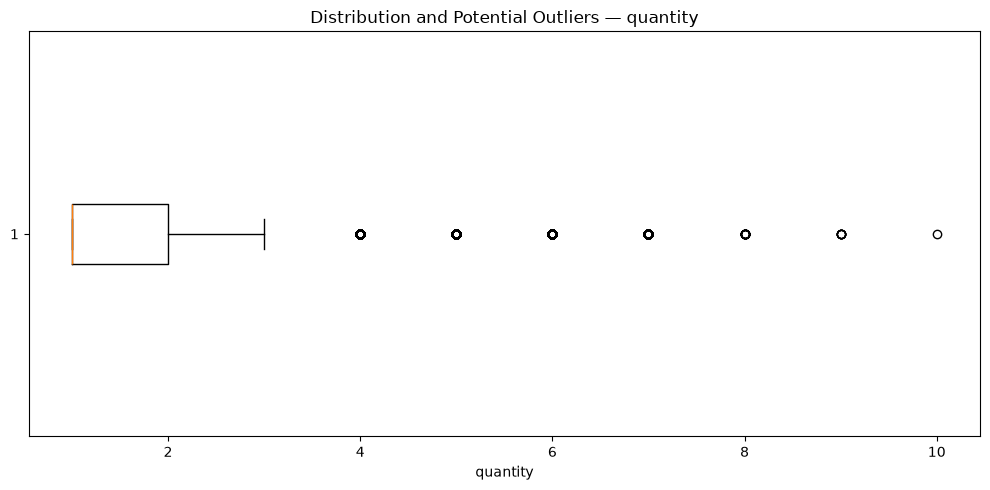

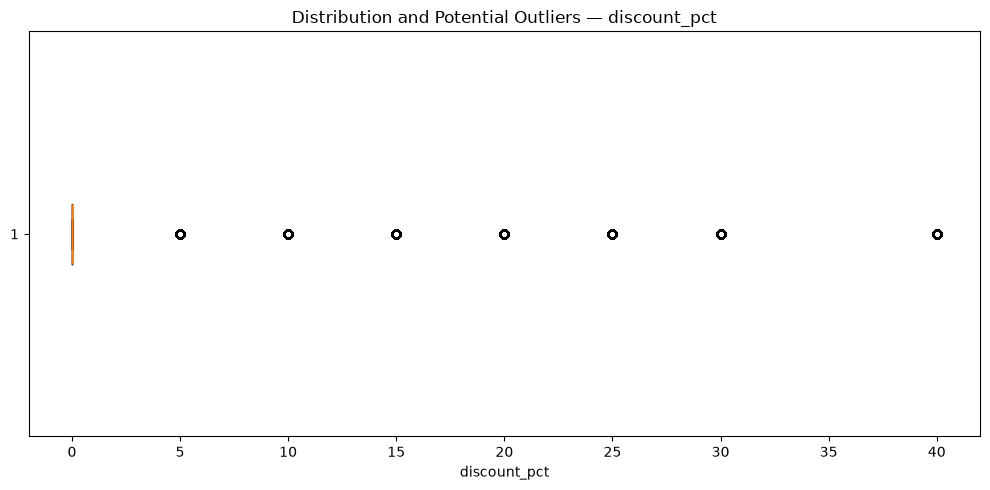

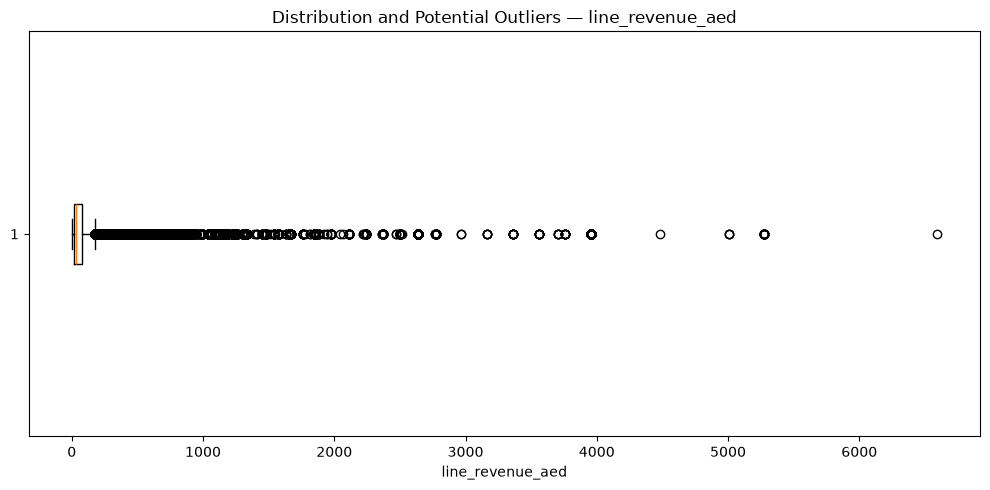

In [22]:
for column in transaction_numeric_columns:
    
    plt.figure(figsize=(10, 5))
    
    plt.boxplot(
        transactions[column].dropna(),
        vert=False
    )
    
    plt.xlabel(column)
    plt.title(f"Distribution and Potential Outliers — {column}")
    plt.tight_layout()
    
    plt.savefig(
        FIGURES_PATH / f"outlier_{column}.png",
        dpi=150,
        bbox_inches="tight"
    )
    
    plt.show()

### Outlier Assessment

Potential outliers were identified using the IQR method for key transaction variables.

- `quantity`: 15,965 records (2.77%) were flagged. These values were retained because larger quantities can represent legitimate bulk purchases.
- `discount_pct`: 108,917 records (18.93%) were flagged. The IQR method is not directly informative for this variable because Q1 and Q3 are both 0%, causing the IQR to equal zero. Non-zero discounts were therefore not treated as erroneous solely based on the IQR rule.
- `line_revenue_aed`: 56,461 records (9.81%) were flagged. These records were retained initially because high-value transactions may represent legitimate purchases. Extreme values will be further investigated using business rules and distribution analysis before any exclusion or transformation.

No observations were removed solely because they were classified as statistical outliers.

In [25]:
date_columns = {
    "customers": ["signup_date"],
    "transactions": ["order_datetime"],
    "digital_engagement": ["year_month"],
    "support_tickets": ["created_at"],
    "churn_labels": ["observation_cutoff"]
}

date_summary = []

for dataset_name, columns in date_columns.items():
    
    df = datasets[dataset_name]
    
    for column in columns:
        
        date_summary.append({
            "Dataset": dataset_name,
            "Column": column,
            "Min_Date": df[column].min(),
            "Max_Date": df[column].max(),
            "Unique_Dates": df[column].nunique()
        })

date_summary = pd.DataFrame(date_summary)

date_summary

,Dataset,Column,Min_Date,Max_Date,Unique_Dates
0,customers,signup_date,2022-02-14 00:00:00,2026-06-21 00:00:00,1554
1,transactions,order_datetime,2024-08-01 06:15:00,2026-07-31 23:58:00,138657
2,digital_engagement,year_month,2024-08-01 00:00:00,2026-07-01 00:00:00,24
3,support_tickets,created_at,2024-08-01 19:32:45,2026-07-30 07:58:59,10410
4,churn_labels,observation_cutoff,2026-04-30 00:00:00,2026-04-30 00:00:00,1


In [26]:
print("Transaction start:", transactions["order_datetime"].min())
print("Transaction end:", transactions["order_datetime"].max())
print("Transaction period:",
      transactions["order_datetime"].max() -
      transactions["order_datetime"].min())

Transaction start: 2024-08-01 06:15:00
Transaction end: 2026-07-31 23:58:00
Transaction period: 729 days 17:43:00


### Date Coverage Findings

- Transaction data covers 1 August 2024 to 31 July 2026, matching the project's defined analysis period.
- Digital engagement data provides 24 monthly observations from August 2024 through July 2026.
- Support ticket records span almost the full transaction period, from August 2024 through July 2026.
- Customer signup dates extend back to February 2022, indicating that some customers existed before the analysis window. These customers are retained because historical signup information can support tenure-related analysis.
- Churn labels use a single observation cutoff of 30 April 2026, consistent with the project's churn modelling design.

In [27]:
transaction_summary = {
    "Transaction rows": len(transactions),
    "Unique orders": transactions["order_id"].nunique(),
    "Unique customers": transactions["customer_id"].nunique(),
    "Unique products": transactions["product_id"].nunique(),
    "Unique stores": transactions["store_id"].nunique()
}

pd.Series(transaction_summary)

Transaction rows    575516
Unique orders       158115
Unique customers     10965
Unique products        391
Unique stores           28
dtype: int64

In [29]:
if "channel" in transactions.columns:
    
    channel_summary = (
        transactions["channel"]
        .value_counts(dropna=False)
        .rename_axis("Channel")
        .reset_index(name="Transaction_Lines")
    )
    
    channel_summary["Percentage"] = (
        channel_summary["Transaction_Lines"] /
        channel_summary["Transaction_Lines"].sum() * 100
    )
    
channel_summary

,Channel,Transaction_Lines,Percentage
0,In-Store,198367,34.47
1,Mobile App,151519,26.33
2,Web,149022,25.89
3,Marketplace,60308,10.48
4,Call Centre,16300,2.83


In [30]:
revenue_summary = pd.Series({
    "Total Revenue (AED)": transactions["line_revenue_aed"].sum(),
    "Average Line Revenue (AED)": transactions["line_revenue_aed"].mean(),
    "Median Line Revenue (AED)": transactions["line_revenue_aed"].median(),
    "Minimum Line Revenue (AED)": transactions["line_revenue_aed"].min(),
    "Maximum Line Revenue (AED)": transactions["line_revenue_aed"].max()
})

revenue_summary

Total Revenue (AED)          49,783,838.38
Average Line Revenue (AED)           86.50
Median Line Revenue (AED)            34.95
Minimum Line Revenue (AED)            1.47
Maximum Line Revenue (AED)        6,590.00
dtype: float64

In [31]:
quantity_summary = pd.Series({
    "Total Units": transactions["quantity"].sum(),
    "Average Units per Line": transactions["quantity"].mean(),
    "Median Units per Line": transactions["quantity"].median(),
    "Minimum Quantity": transactions["quantity"].min(),
    "Maximum Quantity": transactions["quantity"].max()
})

quantity_summary

Total Units              889,360.00
Average Units per Line         1.55
Median Units per Line          1.00
Minimum Quantity               1.00
Maximum Quantity              10.00
dtype: float64

In [40]:
if "is_returned" in transactions.columns:
    
    return_summary = (
        transactions["is_returned"]
        .value_counts(dropna=False)
        .rename_axis("Return_Flag")
        .reset_index(name="Transaction_Lines")
    )
    
    return_summary["Percentage"] = (
        return_summary["Transaction_Lines"] /
        return_summary["Transaction_Lines"].sum() * 100
    )
    
return_summary

,Return_Flag,Transaction_Lines,Percentage
0,0,557896,96.94
1,1,17620,3.06


In [35]:
if "payment_method" in transactions.columns:
    display(
        transactions["payment_method"]
        .value_counts(dropna=False)
        .rename_axis("Payment_Method")
        .reset_index(name="Count")
    )

,Payment_Method,Count
0,Credit Card,222844
1,Debit Card,114531
2,Cash,114466
3,Digital Wallet,93540
4,Buy Now Pay Later,18948
5,Loyalty Points,11187


In [41]:
orders = (
    transactions
    .groupby(["customer_id", "order_id"], as_index=False)
    .agg(
        order_datetime=("order_datetime", "first"),
        channel=("channel", "first"),
        order_value=("line_revenue_aed", "sum"),
        units=("quantity", "sum"),
        lines=("product_id", "count"),
        avg_discount=("discount_pct", "mean")
    )
)

orders.head()

,customer_id,order_id,order_datetime,channel,order_value,units,lines,avg_discount
0,CUST100000,ORD1000000,2025-08-16 18:59:00,Mobile App,529.70,3,2,5.00
1,CUST100000,ORD1000001,2025-09-05 23:20:00,Web,288.40,3,3,0.00
2,CUST100000,ORD1000002,2025-09-13 20:53:00,Mobile App,132.91,6,4,3.75
3,CUST100000,ORD1000003,2025-11-14 15:27:00,Mobile App,97.02,3,2,25.00
4,CUST100000,ORD1000004,2025-11-28 13:39:00,Web,971.16,5,3,1.67


In [42]:
print("Order-level rows:", len(orders))
print("Unique order IDs:", orders["order_id"].nunique())
print("Unique customer IDs:", orders["customer_id"].nunique())

Order-level rows: 158115
Unique order IDs: 158115
Unique customer IDs: 10965


In [43]:
assert len(orders) == orders["order_id"].nunique(), \
    "Order table contains duplicate order IDs."

print("Order-level grain validated successfully.")

Order-level grain validated successfully.


In [44]:
orders.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,158115,10965,CUST106004,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,158115,158115,ORD1000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_datetime,158115,NaN,NaN,NaN,2025-09-10 01:02:16.028839,2024-08-01 06:15:00,2025-03-22 14:24:00,2025-10-07 20:15:00,2026-03-04 16:16:30,2026-07-31 23:58:00,NaN
channel,158115,5,In-Store,47546,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_value,"158,115.00",NaN,NaN,NaN,314.86,1.77,74.34,160.00,359.40,"7,177.94",463.79
units,"158,115.00",NaN,NaN,NaN,5.62,1.00,3.00,5.00,7.00,43.00,4.11
lines,"158,115.00",NaN,NaN,NaN,3.64,1.00,2.00,3.00,5.00,21.00,2.07
avg_discount,"158,115.00",NaN,NaN,NaN,2.93,0.00,0.00,0.00,5.00,40.00,4.62


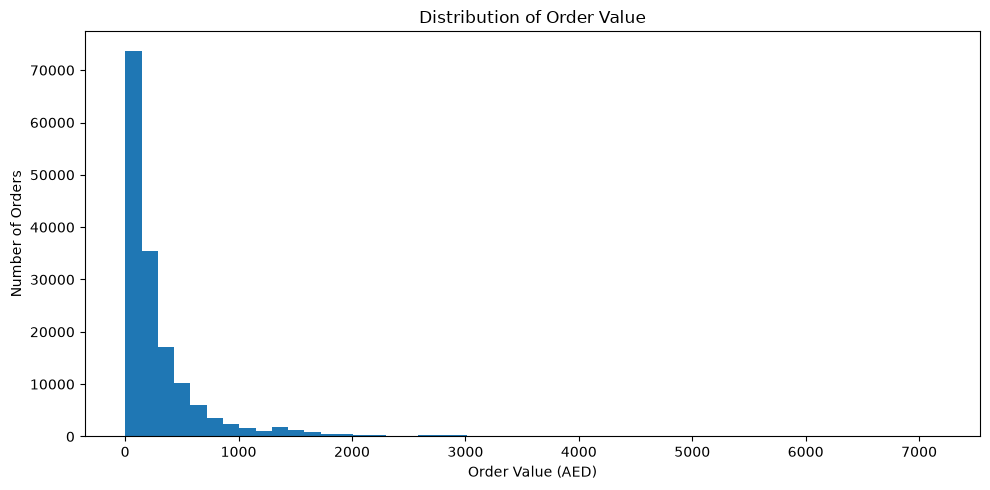

In [45]:
plt.figure(figsize=(10, 5))

plt.hist(
    orders["order_value"],
    bins=50
)

plt.xlabel("Order Value (AED)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Order Value")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "order_value_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [46]:
daily_orders = (
    orders
    .set_index("order_datetime")
    .resample("D")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("order_value", "sum"),
        customers=("customer_id", "nunique")
    )
    .reset_index()
)

daily_orders.head()

,order_datetime,orders,revenue,customers
0,2024-08-01,113,"38,201.93",113
1,2024-08-02,156,"46,447.32",155
2,2024-08-03,127,"42,328.61",126
3,2024-08-04,140,"45,312.74",138
4,2024-08-05,104,"31,587.42",103


In [47]:
customer_overview = (
    orders
    .groupby("customer_id")
    .agg(
        first_order_date=("order_datetime", "min"),
        last_order_date=("order_datetime", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_value", "sum"),
        average_order_value=("order_value", "mean"),
        total_units=("units", "sum"),
        average_basket_units=("units", "mean"),
        average_discount=("avg_discount", "mean")
    )
    .reset_index()
)

customer_overview.head()

,customer_id,first_order_date,last_order_date,frequency,monetary,average_order_value,total_units,average_basket_units,average_discount
0,CUST100000,2025-08-16 18:59:00,2026-05-22 17:51:00,10,"2,828.23",282.82,37,3.70,6.67
1,CUST100001,2024-10-03 17:09:00,2026-07-26 17:04:00,38,"27,700.39",728.96,258,6.79,2.97
2,CUST100002,2024-09-14 23:13:00,2024-09-19 14:14:00,2,"1,821.72",910.86,24,12.00,1.07
3,CUST100003,2025-09-16 17:18:00,2025-11-12 17:13:00,3,684.22,228.07,24,8.00,2.56
4,CUST100004,2024-08-01 16:17:00,2026-07-16 12:24:00,34,"18,344.38",539.54,269,7.91,1.92


In [48]:
print("Customers with at least one order:", len(customer_overview))
print("Average orders per customer:",
      customer_overview["frequency"].mean())
print("Average customer monetary value:",
      customer_overview["monetary"].mean())

Customers with at least one order: 10965
Average orders per customer: 14.419972640218878
Average customer monetary value: 4540.249738258093


In [49]:
customer_overview = customer_overview.merge(
    customers,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

customer_overview.head()

,customer_id,first_order_date,last_order_date,frequency,monetary,average_order_value,total_units,average_basket_units,average_discount,signup_date,age,gender,city,country,household_size,acquisition_channel,loyalty_tier,email_opt_in,sms_opt_in,app_installed
0,CUST100000,2025-08-16 18:59:00,2026-05-22 17:51:00,10,"2,828.23",282.82,37,3.70,6.67,2025-07-17,28,F,Sharjah,UAE,3,In-Store Signup,Silver,1,1,1
1,CUST100001,2024-10-03 17:09:00,2026-07-26 17:04:00,38,"27,700.39",728.96,258,6.79,2.97,2024-10-03,35,M,Riyadh,KSA,4,Organic Search,Silver,1,0,1
2,CUST100002,2024-09-14 23:13:00,2024-09-19 14:14:00,2,"1,821.72",910.86,24,12.00,1.07,2022-03-07,24,M,Abu Dhabi,UAE,8,Organic Search,Gold,1,1,1
3,CUST100003,2025-09-16 17:18:00,2025-11-12 17:13:00,3,684.22,228.07,24,8.00,2.56,2025-09-16,45,M,Dubai,UAE,3,Paid Social,Gold,0,1,0
4,CUST100004,2024-08-01 16:17:00,2026-07-16 12:24:00,34,"18,344.38",539.54,269,7.91,1.92,2022-09-04,45,F,Sharjah,UAE,4,In-Store Signup,Gold,1,0,1


In [50]:
customer_overview[
    [
        "frequency",
        "monetary",
        "average_order_value",
        "total_units",
        "average_basket_units",
        "average_discount"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
frequency,"10,965.00",14.42,13.92,1.00,4.00,10.00,20.00,120.00
monetary,"10,965.00","4,540.25","5,757.90",4.45,858.63,"2,564.02","5,943.02","71,953.20"
average_order_value,"10,965.00",323.44,274.90,4.30,130.56,219.22,466.44,"3,440.01"
total_units,"10,965.00",81.11,78.97,1.00,24.00,58.00,112.00,837.00
average_basket_units,"10,965.00",6.45,4.06,1.00,3.75,5.25,7.53,35.00
average_discount,"10,965.00",3.18,2.27,0.00,1.79,2.79,4.13,30.00


In [51]:
all_customer_ids = set(customers["customer_id"])

ordered_customer_ids = set(orders["customer_id"])

customers_without_orders = all_customer_ids - ordered_customer_ids

print("Total customers:", len(all_customer_ids))
print("Customers with orders:", len(ordered_customer_ids))
print("Customers without orders:", len(customers_without_orders))

Total customers: 12000
Customers with orders: 10965
Customers without orders: 1035


In [52]:
monthly_sales = (
    orders
    .set_index("order_datetime")
    .resample("MS")
    .agg(
        revenue=("order_value", "sum"),
        orders=("order_id", "nunique"),
        customers=("customer_id", "nunique"),
        units=("units", "sum")
    )
    .reset_index()
)

monthly_sales

,order_datetime,revenue,orders,customers,units
0,2024-08-01,"1,255,750.66",4012,2508,23008
1,2024-09-01,"1,340,099.02",4456,2644,25375
2,2024-10-01,"1,448,724.10",4728,2841,26930
3,2024-11-01,"1,526,819.70",5069,2929,28205
4,2024-12-01,"1,892,432.37",6013,3256,34344
5,2025-01-01,"1,575,489.69",4935,2970,27603
6,2025-02-01,"1,594,096.45",5224,3061,29042
7,2025-03-01,"2,301,509.75",7445,3737,41345
8,2025-04-01,"2,064,448.02",6476,3535,36182
9,2025-05-01,"1,813,638.99",5942,3427,33227


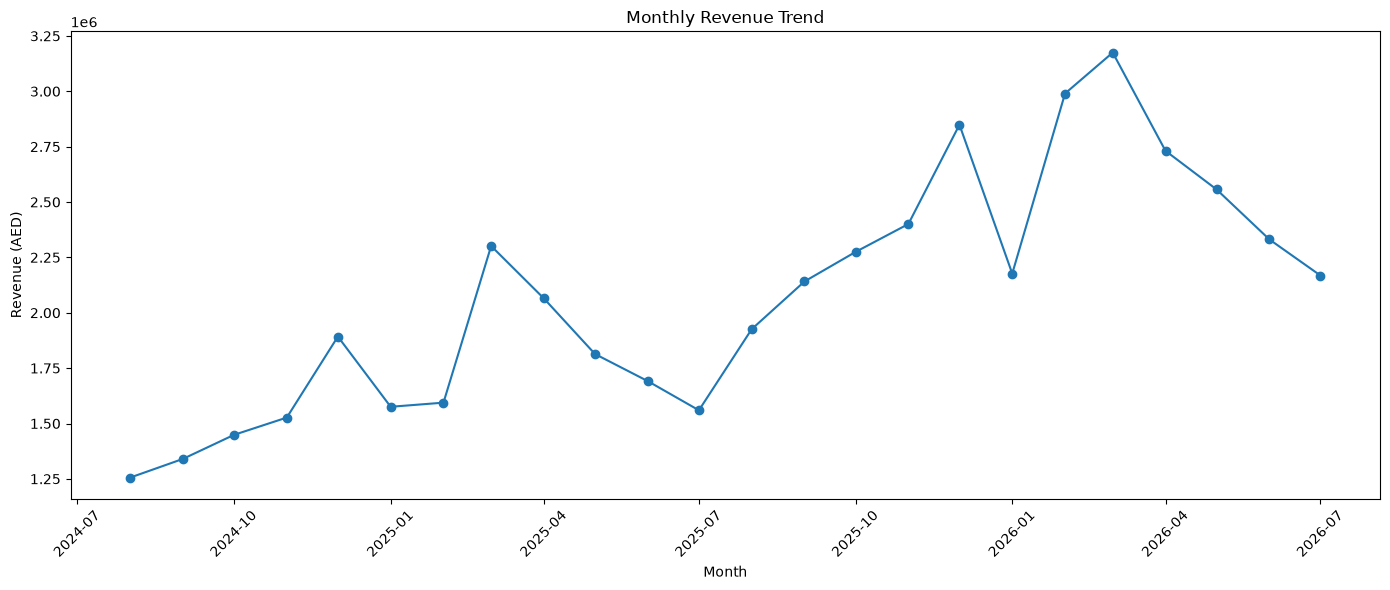

In [53]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_datetime"],
    monthly_sales["revenue"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Revenue (AED)")
plt.title("Monthly Revenue Trend")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "monthly_revenue.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

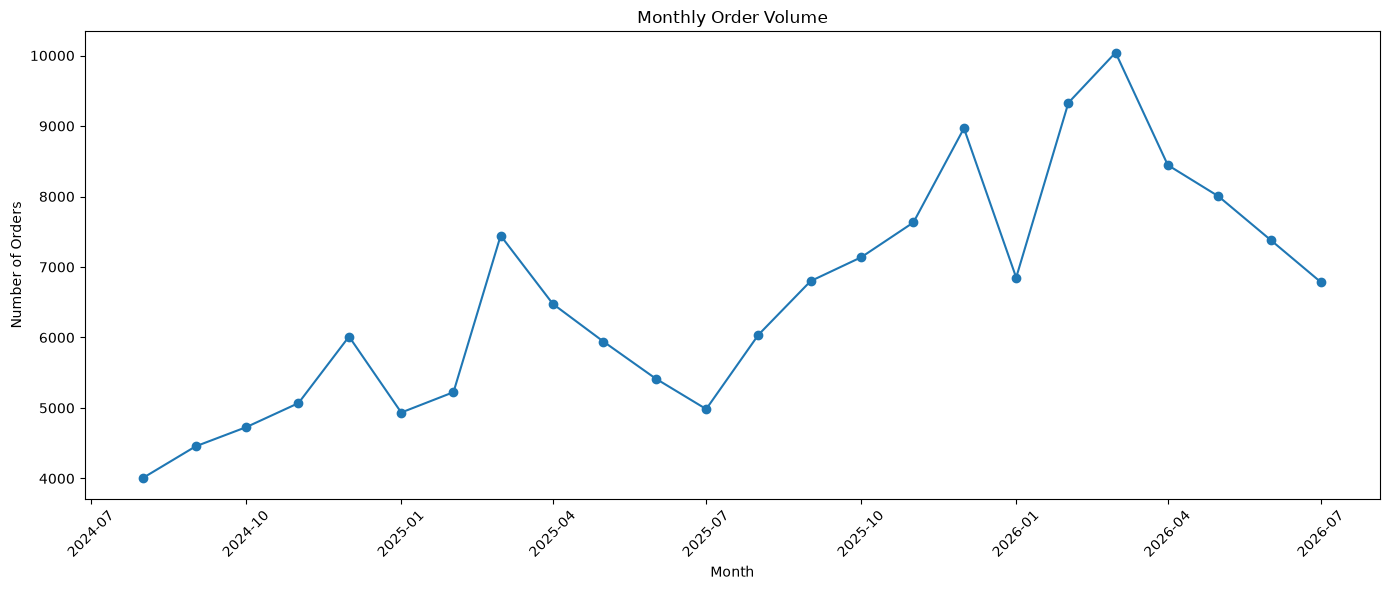

In [54]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_datetime"],
    monthly_sales["orders"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.title("Monthly Order Volume")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "monthly_orders.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [55]:
orders["weekday"] = orders["order_datetime"].dt.day_name()

weekday_order = (
    orders
    .groupby("weekday")["order_id"]
    .nunique()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

weekday_order

weekday
Monday       22616
Tuesday      22850
Wednesday    22635
Thursday     22459
Friday       22590
Saturday     22228
Sunday       22737
Name: order_id, dtype: int64

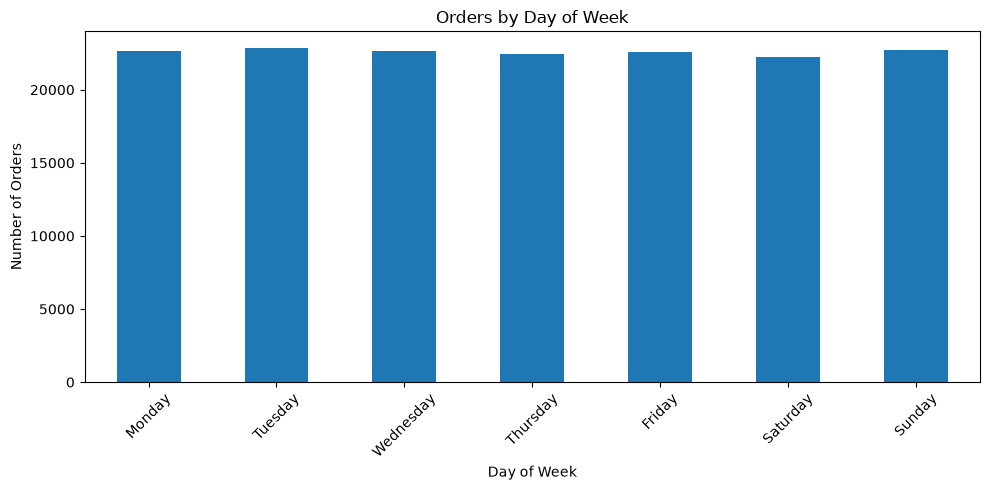

In [56]:
plt.figure(figsize=(10, 5))

weekday_order.plot(kind="bar")

plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.title("Orders by Day of Week")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "orders_by_weekday.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [57]:
monthly_sales["month_number"] = (
    monthly_sales["order_datetime"].dt.month
)

seasonality = (
    monthly_sales
    .groupby("month_number")
    .agg(
        avg_revenue=("revenue", "mean"),
        avg_orders=("orders", "mean")
    )
    .reset_index()
)

seasonality["revenue_index"] = (
    seasonality["avg_revenue"] /
    seasonality["avg_revenue"].mean()
)

seasonality["order_index"] = (
    seasonality["avg_orders"] /
    seasonality["avg_orders"].mean()
)

seasonality

,month_number,avg_revenue,avg_orders,revenue_index,order_index
0,1,"1,876,118.24","5,892.50",0.90,0.89
1,2,"2,292,029.27","7,277.00",1.10,1.10
2,3,"2,738,136.34","8,743.50",1.32,1.33
3,4,"2,397,774.79","7,461.00",1.16,1.13
4,5,"2,185,170.75","6,973.00",1.05,1.06
5,6,"2,011,134.85","6,400.50",0.97,0.97
6,7,"1,863,897.92","5,883.00",0.90,0.89
7,8,"1,590,790.90","5,025.00",0.77,0.76
8,9,"1,740,715.81","5,628.00",0.84,0.85
9,10,"1,861,711.02","5,933.00",0.90,0.90


## Data Quality Decisions

The following decisions will be documented based on the findings from the exploratory analysis:

| Issue | Investigation | Decision | Reason |
|---|---|---|---|
| Exact duplicate rows | Checked across all datasets | Decision based on findings | Avoid removing legitimate records |
| Missing values | Missingness percentage and business meaning reviewed | Decision based on column | Treatment depends on field meaning |
| Repeated order IDs | Expected because transactions are at order-line grain | Retained | Multiple lines can belong to one order |
| Transaction outliers | IQR-based screening performed | Investigate before removal | Large purchases may be legitimate |
| Customers without transactions | Identified from customer master | Retain in customer master | Required for customer-level analysis and must be explicitly addressed |
| Date coverage | Checked across all date fields | Validate against project period | Prevent inconsistent analysis windows |
| Returns | Return flag inspected | Decision based on business meaning | Returned orders may affect revenue and behaviour features |

No records will be removed solely because they are statistically unusual. Cleaning decisions will be based on data quality evidence and business meaning.

In [58]:
# Save order-level dataset
orders.to_csv(
    PROCESSED_DATA_PATH / "orders.csv",
    index=False
)

# Save initial customer-level dataset
customer_overview.to_csv(
    PROCESSED_DATA_PATH / "customer_overview.csv",
    index=False
)

# Save monthly sales summary
monthly_sales.to_csv(
    PROCESSED_DATA_PATH / "monthly_sales.csv",
    index=False
)

print("Processed datasets saved successfully.")

Processed datasets saved successfully.


In [59]:
for file in PROCESSED_DATA_PATH.iterdir():
    print(file.name, "->", file.stat().st_size / (1024 ** 2), "MB")

customer_overview.csv -> 1.7177047729492188 MB
monthly_sales.csv -> 0.0009975433349609375 MB
orders.csv -> 11.87328052520752 MB


In [60]:
print("=" * 70)
print("NOTEBOOK 01 VALIDATION")
print("=" * 70)

print(f"Customers:             {len(customers):,}")
print(f"Products:              {len(products):,}")
print(f"Stores:                {len(stores):,}")
print(f"Transaction lines:     {len(transactions):,}")
print(f"Unique orders:         {transactions['order_id'].nunique():,}")
print(f"Digital records:       {len(digital_engagement):,}")
print(f"Support tickets:       {len(support_tickets):,}")
print(f"Churn labels:          {len(churn_labels):,}")
print("-" * 70)
print(f"Order-level records:   {len(orders):,}")
print(f"Customers with orders: {orders['customer_id'].nunique():,}")
print("-" * 70)
print(f"Transaction start:     {transactions['order_datetime'].min()}")
print(f"Transaction end:       {transactions['order_datetime'].max()}")
print("=" * 70)
print("Notebook 01 completed.")

NOTEBOOK 01 VALIDATION
Customers:             12,000
Products:              391
Stores:                27
Transaction lines:     575,516
Unique orders:         158,115
Digital records:       160,680
Support tickets:       10,411
Churn labels:          7,237
----------------------------------------------------------------------
Order-level records:   158,115
Customers with orders: 10,965
----------------------------------------------------------------------
Transaction start:     2024-08-01 06:15:00
Transaction end:       2026-07-31 23:58:00
Notebook 01 completed.


In [61]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Total customers",
        "Customers with orders",
        "Customers without orders",
        "Transaction lines",
        "Unique orders",
        "Unique products",
        "Unique stores",
        "Transaction start",
        "Transaction end"
    ],
    "Value": [
        len(customers),
        orders["customer_id"].nunique(),
        len(customers) - orders["customer_id"].nunique(),
        len(transactions),
        transactions["order_id"].nunique(),
        transactions["product_id"].nunique(),
        transactions["store_id"].nunique(),
        transactions["order_datetime"].min(),
        transactions["order_datetime"].max()
    ]
})

quality_summary

,Metric,Value
0,Total customers,12000
1,Customers with orders,10965
2,Customers without orders,1035
3,Transaction lines,575516
4,Unique orders,158115
5,Unique products,391
6,Unique stores,28
7,Transaction start,2024-08-01 06:15:00
8,Transaction end,2026-07-31 23:58:00


In [62]:
quality_summary.to_csv(
    TABLES_PATH / "data_quality_summary.csv",
    index=False
)

In [64]:
print("Negative quantity:", (transactions["quantity"] < 0).sum())
print("Zero quantity:", (transactions["quantity"] == 0).sum())

print("Negative unit price:", (transactions["unit_price_aed"] < 0).sum())
print("Zero unit price:", (transactions["unit_price_aed"] == 0).sum())

print("Discount < 0:", (transactions["discount_pct"] < 0).sum())
print("Discount > 100:", (transactions["discount_pct"] > 100).sum())

print("Negative revenue:", (transactions["line_revenue_aed"] < 0).sum())

Negative quantity: 0
Zero quantity: 0
Negative unit price: 0
Zero unit price: 0
Discount < 0: 0
Discount > 100: 0
Negative revenue: 0
